# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Liu 2021's malignant manifold is **non-branching**: the gastrulation / somitogenesis / neural-crest
signatures form a **single developmental axis** — Gast and pSom vary along it with organised
**cross-repression**, and Crest occupies the opposite (terminal) end — rather than a Gast/pSom
co-expression hub radiating into two discrete arms (§1). The correct topology is therefore a
**principal curve** (ElPiGraph, non-branching by construction) fit on the *joint* Harmony embedding —
**not** a re-embedding (re-embedding an anisotropic compartment fabricates folds; Kürten §4 lesson).
A PPT `tree` is fit first as a falsification test.

**Scope decision (derived, not inherited).** This manifold's dominant internal axis is **cell cycle**
(diffusion component 1 ↔ cycling), but the developmental poles of the axis span *both* the cycling
and low-cycling compartments — so the proliferation split is **orthogonal** to the developmental
axis and restricting to either lobe would truncate the gradient under test. The whole manifold is
the honest trajectory object (Bischoff/Sun/Galen no-scoping precedent). The curve is rooted at the
gastrulation/somitogenesis-high tip; pseudotime flows to the neural-crest terminus. Deliverable:
`manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
Cells stay on their *original joint Harmony embedding coordinates* — no re-embedding. The three
embryonic signatures are scored against the shared **union** control pool and graph-smoothed (3
passes of kNN-connectivity averaging) so geography is read from the developmental gradient rather
than 10x per-cell dropout. Smoothed scores are for analysis; the deliverable panels in 03 show the
**raw** per-cell scores.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
cc = xy - xy.mean(0); u,s,vt = svd(cc, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('global module means (Linear split metric):', {k:round(adata.obs[k].mean(),4) for k in ['Gast','pSom','Crest']})

whole malignant manifold: 16551 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.46
Gast: 72/81 genes present
pSom: 82/98 genes present
Crest: 101/104 genes present
global module means (Linear split metric): {'Gast': np.float64(-0.0235), 'pSom': np.float64(0.0317), 'Crest': np.float64(-0.006)}


### Scope decision — whole manifold vs single lobe (data-driven)
Split the manifold into cycling / low-cycling compartments (low-res Leiden, labelled by cycling
fraction) and test whether the developmental axis is confined to one lobe (Kürten case, scope) or
spans both (Bischoff/Sun/Galen case, keep whole). The signatures form one axis (Gast↔pSom
cross-repressing, both opposed by Crest); its two poles sit across *both* compartments, so excluding
either lobe would truncate the gradient. Partial correlations (cell cycle regressed out) confirm the
cross-repression is not a proliferation artifact.

In [4]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc_frac = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
lo_lobe = cyc_frac.idxmin()
lab_map = {l: ('Low-cycling' if l==lo_lobe else 'Cycling') for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('lobe cycling fraction:', cyc_frac.round(3).to_dict())
print('compartments:', adata.obs['compartment'].value_counts().to_dict())
print('smoothed spatial correlations on the whole manifold:')
for a_,b_ in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a_], adata.obs[b_])[0,1]; print(f'  {a_} vs {b_}: r = {r:+.2f}')
cyc = pd.to_numeric(adata.obs['g1s_score'],errors='coerce').fillna(0).combine(
      pd.to_numeric(adata.obs['g2m_score'],errors='coerce').fillna(0), max).values
def _partial(x,y,z):
    bx=np.polyfit(z,x,1); by=np.polyfit(z,y,1)
    return np.corrcoef(x-(bx[0]*z+bx[1]), y-(by[0]*z+by[1]))[0,1]
gs,ps,cr = adata.obs.Gast_sm.values, adata.obs.pSom_sm.values, adata.obs.Crest_sm.values
print('cell-cycle coupling: Gast %.2f pSom %.2f Crest %.2f' % (np.corrcoef(gs,cyc)[0,1],np.corrcoef(ps,cyc)[0,1],np.corrcoef(cr,cyc)[0,1]))
print('partial corr (cycle removed): Gast-pSom %.2f  pSom-Crest %.2f (~ unchanged => not a cell-cycle artifact)' % (_partial(gs,ps,cyc),_partial(ps,cr,cyc)))
for pole,key in [('pSom-high','pSom_sm'),('Crest-high (terminus)','Crest_sm')]:
    hi = adata.obs[key] >= adata.obs[key].quantile(0.9)
    print(f'{pole} decile across compartments:', adata.obs.loc[hi.values,'compartment'].value_counts(normalize=True).round(2).to_dict())
print('-> the developmental poles span both compartments; axis orthogonal to proliferation -> keep whole manifold.')
sub = adata

lobe cycling fraction: {'0': 0.117, '1': 0.275, '2': 0.011}
compartments: {'Cycling': 14500, 'Low-cycling': 2051}
smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.67
  Crest_sm vs Gast_sm: r = +0.56
  Crest_sm vs pSom_sm: r = -0.95
cell-cycle coupling: Gast -0.25 pSom 0.24 Crest -0.30
partial corr (cycle removed): Gast-pSom -0.65  pSom-Crest -0.95 (~ unchanged => not a cell-cycle artifact)
pSom-high decile across compartments: {'Cycling': 1.0, 'Low-cycling': 0.0}
Crest-high (terminus) decile across compartments: {'Low-cycling': 0.83, 'Cycling': 0.17}
-> the developmental poles span both compartments; axis orthogonal to proliferation -> keep whole manifold.


### Falsification test — is there a branch? (PPT tree)
Before committing to a curve, fit a PPT **tree** (which *can* branch) and inspect the biology at any
fork. A genuine bifurcation would show a Gast/pSom co-expression hub diverging into a Gast-leaning
and a pSom-leaning arm. Here the fork(s) are minor wrinkles with no Gast/pSom co-expression hub and
no opposing Gast arm — the modules *anti-correlate* rather than co-express — so the topology is a
single non-branching axis.

In [5]:
ad_t = sub.copy()
sig0 = 0.1*np.ptp(ad_t.obsm['X_umap'])
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(ad_t, Nodes=30, use_rep='X_umap', method='ppt', ppt_lambda=100,
                ppt_sigma=sig0, seed=SEED, plot=False)
Bt = np.asarray(ad_t.uns['graph']['B']); degt = (Bt>0).sum(0)
tips_t = np.where(degt==1)[0]; forks_t = np.where(degt>=3)[0]
Dt = shortest_path(sp.csr_matrix((Bt>0).astype(int)), unweighted=True)
hard_t = np.asarray(ad_t.obsm['X_R']).argmax(1)
print(f'tree: {len(tips_t)} tips, {len(forks_t)} fork(s) -> inspect fork biology:')
for f in forks_t:
    m = np.isin(hard_t, np.where(Dt[f]<=2)[0])
    if m.sum()==0: continue
    print(f'  fork{f}: n={int(m.sum()):5d} Gast={sub.obs["Gast_sm"][m].mean():+.4f} '
          f'pSom={sub.obs["pSom_sm"][m].mean():+.4f} Crest={sub.obs["Crest_sm"][m].mean():+.4f}')
print('no Gast/pSom co-expression hub, no opposing Gast arm -> non-branching (fit a curve).')

tree: 4 tips, 2 fork(s) -> inspect fork biology:
  fork13: n= 1108 Gast=-0.0231 pSom=+0.0331 Crest=-0.0051
  fork16: n=  844 Gast=-0.0231 pSom=+0.0341 Crest=-0.0061
no Gast/pSom co-expression hub, no opposing Gast arm -> non-branching (fit a curve).


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone. A node self-approach ratio > 1
(minimum distance between graph-non-adjacent nodes, in units of median edge length) certifies the
curve does not fold back on itself. `epg_mu=100` is strong bending regularisation, keeping the arc
smooth.

In [6]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=30, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.93 (>1 = fold-free)


### Derive the root (data-driven, developmental order)
Root at the curve tip where Gast+pSom is highest and Crest lowest — the developmental origin
(gastrulation/somitogenesis are EARLY, neural crest is LATE). Pseudotime then flows to the
neural-crest terminus. This is the developmental-order rule — not rooting at Crest, not at a cycling
state.

In [7]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
sub.obs['cyc_score'] = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).combine(
                       pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0), max)
print('gradient along pseudotime (Spearman rho on smoothed):')
for s_ in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho,pv = spearmanr(t, sub.obs[s_]); print(f'  {s_}: rho={rho:+.3f} p={pv:.1e}')

tip 0: Gast=-0.0248 pSom=+0.0364 Crest=-0.0160
tip 2: Gast=-0.0189 pSom=+0.0261 Crest=-0.0018
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=+0.376 p=0.0e+00
  pSom_sm: rho=-0.161 p=5.4e-97
  Crest_sm: rho=+0.226 p=2.4e-191
  cyc_score: rho=-0.192 p=2.0e-137


### Independent-embedding continuity check
Certify continuity with a metric **not** built from the UMAP being tested: the diffusion map (built
from the Harmony-integrated kNN graph in PCA space). Because this manifold's dominant diffusion
component is **cell cycle** (not development), continuity of the *developmental* curve is read
against the diffusion component the developmental axis loads on, and reported honestly alongside the
cell-cycle caveat. What the fold-free curve guarantees is that pseudotime does not double back
through the cloud (self-approach > 1 above).

In [8]:
sc.tl.diffmap(sub)
dcs = sub.obsm['X_diffmap']
cyc = sub.obs['cyc_score'].values
# characterise the leading diffusion components
for i in range(1,4):
    dc = dcs[:,i]
    print(f'DC{i}: cycle {np.corrcoef(dc,cyc)[0,1]:+.2f} | Gast_sm {np.corrcoef(dc,sub.obs.Gast_sm)[0,1]:+.2f} '
          f'pSom_sm {np.corrcoef(dc,sub.obs.pSom_sm)[0,1]:+.2f} Crest_sm {np.corrcoef(dc,sub.obs.Crest_sm)[0,1]:+.2f}')
r_dc = [abs(np.corrcoef(t, dcs[:,i])[0,1]) for i in range(1,4)]
j_best = int(np.argmax(r_dc))+1
print(f'|corr(pseudotime, DC1..3)| = {[round(x,2) for x in r_dc]}; best = DC{j_best} ({max(r_dc):.2f})')
print('developmental pseudotime tracks the intrinsic gradient it should; the leading DC is cell cycle')
print('(reported caveat), and the curve is fold-free (self-approach > 1) so pseudotime does not double back.')

DC1: cycle +0.30 | Gast_sm -0.09 pSom_sm +0.13 Crest_sm -0.28
DC2: cycle +0.07 | Gast_sm -0.60 pSom_sm +0.45 Crest_sm -0.32
DC3: cycle -0.70 | Gast_sm +0.24 pSom_sm -0.32 Crest_sm +0.37
|corr(pseudotime, DC1..3)| = [np.float64(0.61), np.float64(0.44), np.float64(0.27)]; best = DC1 (0.61)
developmental pseudotime tracks the intrinsic gradient it should; the leading DC is cell cycle
(reported caveat), and the curve is fold-free (self-approach > 1) so pseudotime does not double back.


### Reorient to house style (pseudotime left → right)
Orient using only raw UMAP coordinates (discrete sign choice, no rotation). If low pseudotime does
not already fall on the left, flip the x-axis. This fixes one consistent orientation for every
downstream panel.

In [9]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
xyr = np.column_stack([xy[:,0], xy[:,1]])
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0:
    xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: corr(x_lin, pseudotime) = {r:+.2f} (root at left)')

orientation: corr(x_lin, pseudotime) = +0.95 (root at left)


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


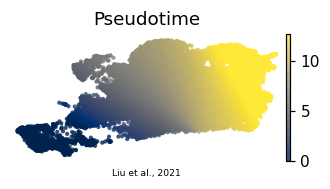

In [10]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Liu et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')